# EDA – Bộ dữ liệu chữ số viết tay MNIST

**Mục tiêu:** hiểu cấu trúc, chất lượng và đặc điểm của dữ liệu trước khi xây dựng mô hình phân loại.

**Mục lục**
1. Thiết lập và đọc dữ liệu
2. Tổng quan train / test
3. Kiểm tra chất lượng dữ liệu
4. Ảnh mẫu
5. Phân bố nhãn
6. Phân bố độ xám pixel
7. Thống kê pixel (toàn cục và theo vị trí)
8. Thống kê theo từng ảnh
9. Ảnh trung bình và độ lệch chuẩn theo nhãn
10. Mức độ giống nhau giữa các lớp
11. Ảnh bất thường (outlier)
12. So sánh train và test
13. Kết luận và đề xuất tiền xử lý

# 1. Thiết lập và đọc dữ liệu

In [5]:
from pathlib import Path
import sys

# Find the project root from the notebook's working directory.
PROJECT_ROOT = Path.cwd().resolve()

# Run until found the (PROJECT_ROOT / "requirements.txt")
while not (PROJECT_ROOT / "requirements.txt").is_file():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Cannot find the project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

# Allow imports starting with "src".
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data" / "raw"

In [6]:
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 100
rng = np.random.default_rng(42)

In [7]:
train_data = np.load(DATA_DIR / "mnist_train.npz")
test_data = np.load(DATA_DIR / "mnist_test.npz")

X_train, y_train = train_data["X"], train_data["y"]
X_test, y_test = test_data["X"], test_data["y"]

# 2. Tổng quan train / test

In [8]:
def overview(X, y):
    return {
        "Số ảnh": len(X),
        "Shape X": X.shape,
        "Shape y": y.shape,
        "Kiểu dữ liệu X": str(X.dtype),
        "Kiểu dữ liệu y": str(y.dtype),
        "Pixel min": int(X.min()),
        "Pixel max": int(X.max()),
        "Số nhãn khác nhau": len(np.unique(y)),
        "Nhãn min - max": f"{y.min()} - {y.max()}",
    }

pd.DataFrame({"Train": overview(X_train, y_train), "Test": overview(X_test, y_test)})

,Train,Test
Số ảnh,60000,10000
Shape X,"(60000, 28, 28)","(10000, 28, 28)"
Shape y,"(60000,)","(10000,)"
Kiểu dữ liệu X,uint8,uint8
Kiểu dữ liệu y,int64,int64
Pixel min,0,0
Pixel max,255,255
Số nhãn khác nhau,10,10
Nhãn min - max,0 - 9,0 - 9


# 3. Kiểm tra chất lượng dữ liệu

In [9]:
def image_hashes(X):
    return [hashlib.md5(img.tobytes()).hexdigest() for img in X]

h_train = image_hashes(X_train)
h_test = image_hashes(X_test)

# Ảnh trùng lặp trong từng tập
dup_train = len(h_train) - len(set(h_train))
dup_test = len(h_test) - len(set(h_test))

# Ảnh xuất hiện ở cả train và test (rò rỉ dữ liệu)
overlap = len(set(h_train) & set(h_test))

# Ảnh toàn 0 (ảnh trống)
blank_train = int((X_train.reshape(len(X_train), -1).max(axis=1) == 0).sum())
blank_test = int((X_test.reshape(len(X_test), -1).max(axis=1) == 0).sum())

# Nhãn hợp lệ 0..9
valid_labels = set(range(10))
bad_train = int((~np.isin(y_train, list(valid_labels))).sum())
bad_test = int((~np.isin(y_test, list(valid_labels))).sum())

pd.DataFrame(
    {
        "Train": [dup_train, blank_train, bad_train],
        "Test": [dup_test, blank_test, bad_test],
    },
    index=["Ảnh trùng lặp", "Ảnh trống (toàn 0)", "Nhãn ngoài 0-9"],
).assign(**{"Train∩Test": [overlap, "-", "-"]})

,Train,Test,Train∩Test
Ảnh trùng lặp,0,0,0
Ảnh trống (toàn 0),0,0,-
Nhãn ngoài 0-9,0,0,-


# 4. Ảnh mẫu

Lấy ngẫu nhiên 10 ảnh cho **mỗi nhãn** (mỗi hàng là một nhãn) để thấy sự đa dạng trong cùng một lớp.

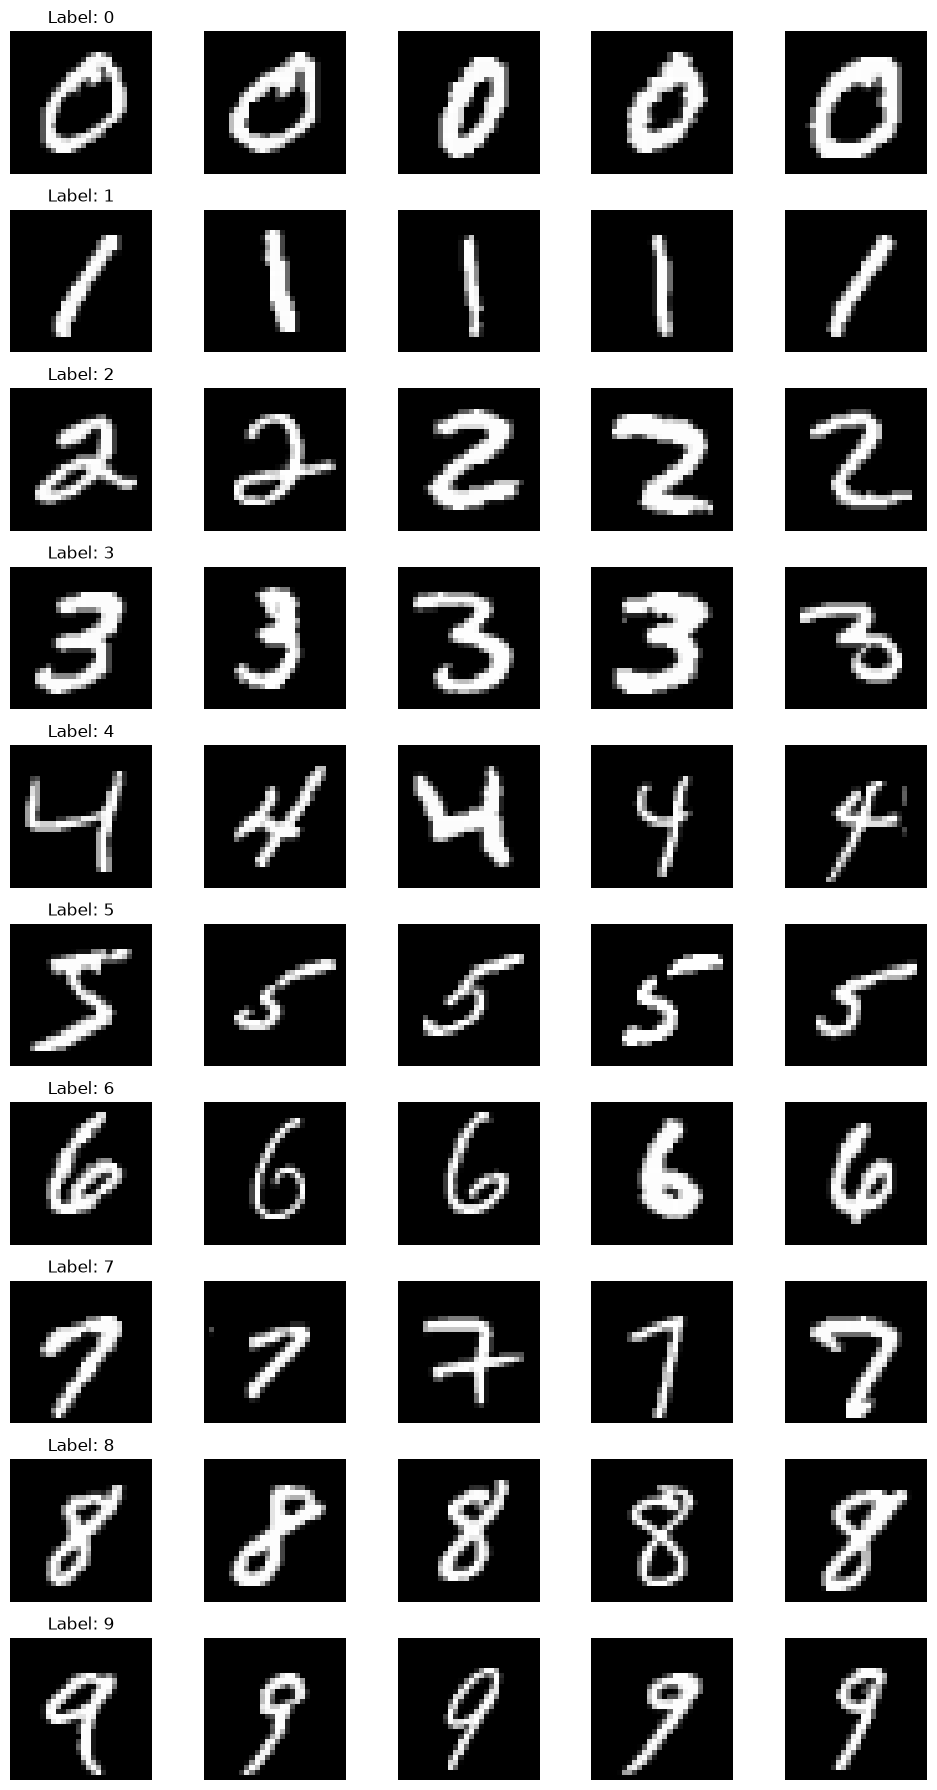

In [10]:
fig, ax = plt.subplots(10, 5, figsize=(10, 18))

for i in range(10):
    images = X_train[y_train == i]

    for j in range(5):
        image = images[j]

        ax[i, j].imshow(image, cmap="gray")
        ax[i, j].axis("off")

        if j == 0:
           ax[i, j].set_title(f"Label: {i}")

plt.tight_layout()
plt.show()

# 5. Phân bố số lượng ảnh theo nhãn

In [11]:
labels, counts_train = np.unique(y_train, return_counts=True)
_, counts_test = np.unique(y_test, return_counts=True)

dist = pd.DataFrame(
    {
        "Train": counts_train,
        "Train (%)": (counts_train / counts_train.sum() * 100).round(2),
        "Test": counts_test,
        "Test (%)": (counts_test / counts_test.sum() * 100).round(2),
    },
    index=labels,
)
dist.index.name = "Label"
display(dist)

print(f"Tỷ lệ lớp lớn nhất / nhỏ nhất (train): {counts_train.max() / counts_train.min():.2f}")
print(f"Lớp nhiều nhất: {labels[counts_train.argmax()]} | ít nhất: {labels[counts_train.argmin()]}")

,Train,Train (%),Test,Test (%)
Label,,,,
0,5923,9.87,980,9.80
1,6742,11.24,1135,11.35
2,5958,9.93,1032,10.32
3,6131,10.22,1010,10.10
4,5842,9.74,982,9.82
5,5421,9.04,892,8.92
6,5918,9.86,958,9.58
7,6265,10.44,1028,10.28
8,5851,9.75,974,9.74


Tỷ lệ lớp lớn nhất / nhỏ nhất (train): 1.24
Lớp nhiều nhất: 1 | ít nhất: 5


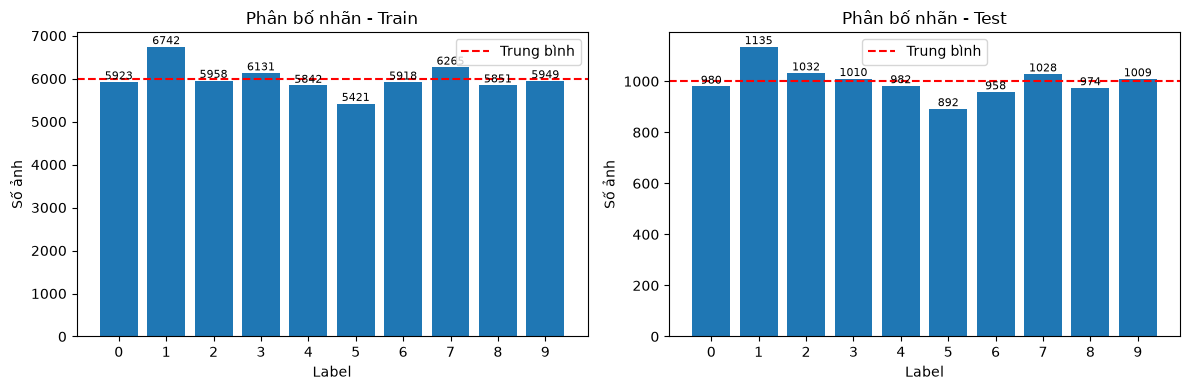

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for a, c, name in zip(ax, [counts_train, counts_test], ["Train", "Test"]):
    bars = a.bar(labels, c)
    a.axhline(c.mean(), color="red", linestyle="--", label="Trung bình")
    a.set_title(f"Phân bố nhãn - {name}")
    a.set_xlabel("Label")
    a.set_ylabel("Số ảnh")
    a.set_xticks(range(10))
    a.bar_label(bars, fontsize=8)
    a.legend()
plt.tight_layout()
plt.show()

**Nhận xét:** các nhãn *gần cân bằng* chứ không hoàn toàn đều (xem tỷ lệ lớp lớn nhất / nhỏ nhất ở trên). Mức lệch này nhỏ, thường không cần cân bằng lại lớp, nhưng nên dùng **stratified split** khi chia validation và đánh giá bằng cả accuracy lẫn F1 macro.

# 6. Phân bố giá trị độ xám pixel

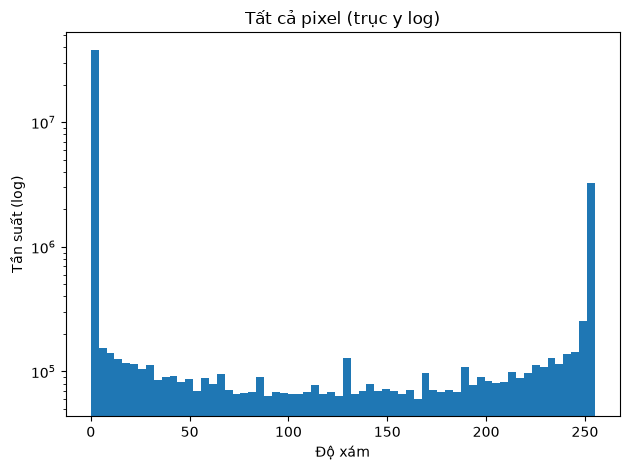

Số giá trị độ xám khác nhau: 256
Pixel >= 250: 7.36%
Pixel trong (0, 250): 11.76%


In [13]:
pix = X_train.ravel()


plt.hist(pix, bins=64)
plt.yscale("log")
plt.title("Tất cả pixel (trục y log)")
plt.xlabel("Độ xám")
plt.ylabel("Tần suất (log)")


plt.tight_layout()
plt.show()

print("Số giá trị độ xám khác nhau:", len(np.unique(pix)))
print(f"Pixel >= 250: {np.mean(pix >= 250) * 100:.2f}%")
print(f"Pixel trong (0, 250): {np.mean((pix > 0) & (pix < 250)) * 100:.2f}%")

**Nhận xét:** phần lớn pixel là nền đen (0), một phần đáng kể gần bão hòa (~255) ở nét chữ; pixel có giá trị trung gian chủ yếu nằm ở rìa nét (do khử răng cưa). Phân phối này lệch mạnh nên histogram thường cần thang log mới nhìn rõ.

# 7. Thống kê pixel

In [14]:
print("Mean:", X_train.mean())
print("Std:", X_train.std())
print("Tỷ lệ pixel bằng 0:", np.mean(X_train == 0))
print("Tỷ lệ pixel khác 0:", np.mean(X_train != 0))

# Sau khi chia 255 (dùng cho chuẩn hóa)
print()
print("Mean (thang 0-1):", X_train.mean() / 255)
print("Std  (thang 0-1):", X_train.std() / 255)

Mean: 33.318421449829934
Std: 78.56748998339798
Tỷ lệ pixel bằng 0: 0.8087977040816327
Tỷ lệ pixel khác 0: 0.19120229591836735

Mean (thang 0-1): 0.1306604762738429
Std  (thang 0-1): 0.30810780385646264


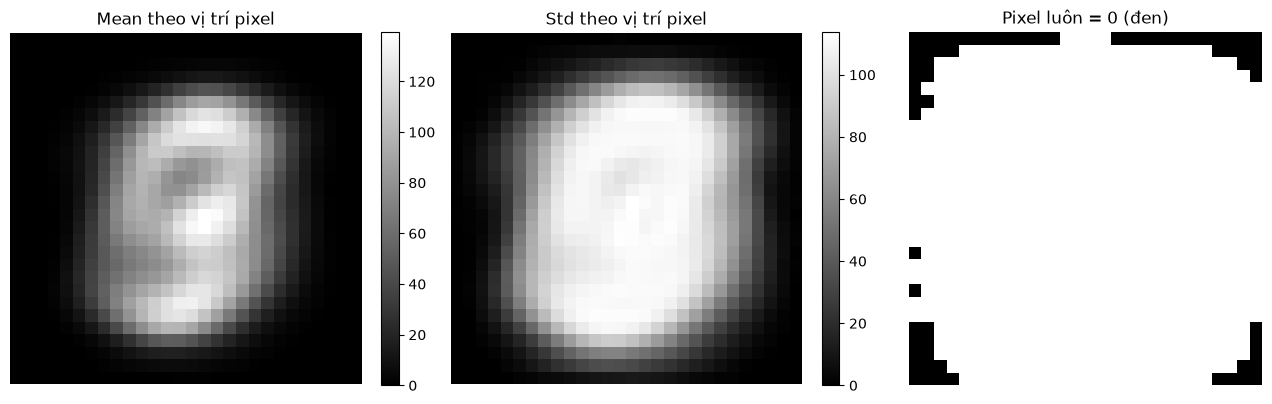

Số vị trí pixel luôn bằng 0 trong train: 67 / 784 (8.5%)


In [15]:
mean_map = X_train.mean(axis=0)
std_map = X_train.std(axis=0)
dead = (X_train.max(axis=0) == 0)

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
im0 = ax[0].imshow(mean_map, cmap="gray"); 
ax[0].set_title("Mean theo vị trí pixel")
im1 = ax[1].imshow(std_map, cmap="gray"); 
ax[1].set_title("Std theo vị trí pixel")
ax[2].imshow(dead, cmap="gray_r"); 
ax[2].set_title("Pixel luôn = 0 (đen)")
for a, im in zip(ax[:2], [im0, im1]):
    plt.colorbar(im, ax=a, fraction=0.046)
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

print(f"Số vị trí pixel luôn bằng 0 trong train: {dead.sum()} / 784 ({dead.mean() * 100:.1f}%)")

**Nhận xét:** thông tin tập trung ở vùng giữa ảnh; viền ngoài gần như không có nét nên mang ít thông tin. Các vị trí luôn bằng 0 có thể bỏ khi dùng mô hình cổ điển (hoặc để PCA xử lý).

# 8. Thống kê theo từng ảnh

In [16]:
flat = X_train.reshape(len(X_train), -1)

per_image = pd.DataFrame(
    {
        "label": y_train,
        "nonzero": (flat > 0).sum(axis=1),          # số pixel có nét
        "mean_intensity": flat.mean(axis=1),
        "sum_intensity": flat.sum(axis=1, dtype=np.int64),
    }
)

# Bounding box của chữ số
rows_any = (X_train > 0).any(axis=2)
cols_any = (X_train > 0).any(axis=1)
valid = rows_any.any(axis=1)
per_image["height"] = np.where(valid, 28 - np.argmax(rows_any[:, ::-1], axis=1) - np.argmax(rows_any, axis=1), 0)
per_image["width"] = np.where(valid, 28 - np.argmax(cols_any[:, ::-1], axis=1) - np.argmax(cols_any, axis=1), 0)

display(per_image.describe().round(2))
display(per_image.groupby("label")[["nonzero", "mean_intensity", "height", "width"]].mean().round(2))

,label,nonzero,mean_intensity,sum_intensity,height,width
count,60000.00,60000.00,60000.00,60000.00,60000.00,60000.00
mean,4.45,149.90,33.32,26121.64,19.74,15.68
std,2.89,41.46,11.04,8656.31,0.99,3.86
min,0.00,34.00,6.49,5086.00,9.00,2.00
25%,2.00,122.00,25.33,19858.00,20.00,14.00
50%,4.00,150.00,32.48,25467.00,20.00,16.00
75%,7.00,178.00,40.26,31562.00,20.00,19.00
max,9.00,351.00,101.38,79483.00,20.00,20.00


,nonzero,mean_intensity,height,width
label,,,,
0,191.97,44.22,19.56,18.01
1,85.85,19.38,19.99,9.35
2,168.81,37.99,19.28,18.27
3,163.34,36.09,19.87,16.48
4,141.81,30.95,19.88,16.38
5,152.33,32.83,19.02,17.98
6,156.93,35.01,19.94,15.23
7,131.40,29.20,19.86,16.04
8,173.32,38.29,19.90,15.85


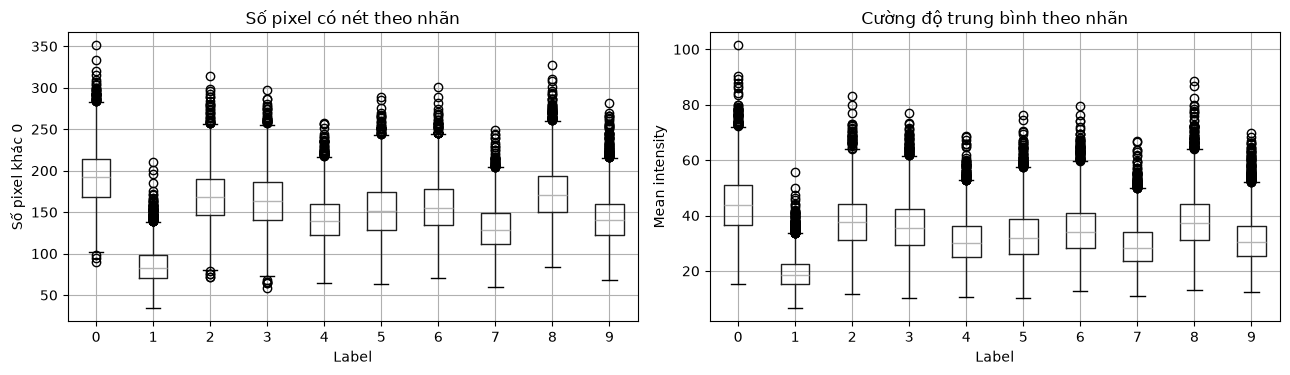

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
per_image.boxplot(column="nonzero", by="label", ax=ax[0])
ax[0].set_title("Số pixel có nét theo nhãn")
ax[0].set_xlabel("Label"); ax[0].set_ylabel("Số pixel khác 0")

per_image.boxplot(column="mean_intensity", by="label", ax=ax[1])
ax[1].set_title("Cường độ trung bình theo nhãn")
ax[1].set_xlabel("Label"); ax[1].set_ylabel("Mean intensity")

plt.suptitle("")
plt.tight_layout()
plt.show()

**Nhận xét:** số pixel có nét khác nhau rõ theo nhãn (ví dụ chữ số 1 ít nét nhất, 0 và 8 nhiều nét hơn), nên đặc trưng đơn giản này đã mang một phần thông tin phân biệt lớp.

# 9. Ảnh trung bình và độ lệch chuẩn theo nhãn

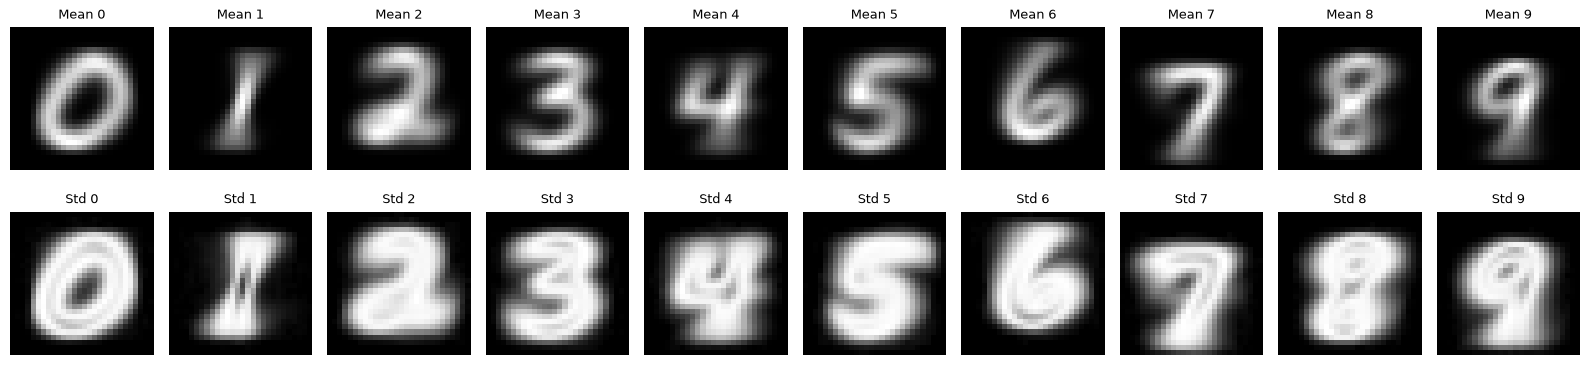

In [18]:
mean_imgs = np.stack([X_train[y_train == d].mean(axis=0) for d in range(10)])
std_imgs = np.stack([X_train[y_train == d].std(axis=0) for d in range(10)])

fig, axes = plt.subplots(2, 10, figsize=(16, 4))
for d in range(10):
    axes[0, d].imshow(mean_imgs[d], cmap="gray")
    axes[0, d].set_title(f"Mean {d}", fontsize=9)
    axes[1, d].imshow(std_imgs[d], cmap="gray")
    axes[1, d].set_title(f"Std {d}", fontsize=9)
for a in axes.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

**Nhận xét:** ảnh mean cho thấy dạng điển hình của từng chữ số; ảnh std sáng ở vùng nét hay thay đổi (độ nghiêng, độ dày, kiểu viết). Lớp có ảnh mean càng mờ thì càng đa dạng cách viết.

# 10. Mức độ giống nhau giữa các lớp

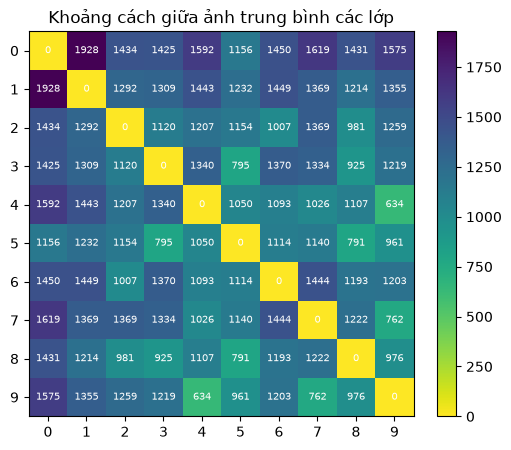

5 cặp lớp gần nhau nhất (dễ nhầm lẫn nhất):
  4 - 9: 633.6
  7 - 9: 761.6
  5 - 8: 791.4
  3 - 5: 794.6
  3 - 8: 924.8


In [19]:
# Khoảng cách Euclid giữa các ảnh trung bình
M = mean_imgs.reshape(10, -1)
D = np.linalg.norm(M[:, None, :] - M[None, :, :], axis=2)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(D, cmap="viridis_r")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_title("Khoảng cách giữa ảnh trung bình các lớp")
for i in range(10):
    for j in range(10):
        ax.text(j, i, f"{D[i, j]:.0f}", ha="center", va="center", color="white", fontsize=7)
plt.colorbar(im, fraction=0.046)
plt.show()

pairs = [(i, j, D[i, j]) for i in range(10) for j in range(i + 1, 10)]
pairs = sorted(pairs, key=lambda t: t[2])
print("5 cặp lớp gần nhau nhất (dễ nhầm lẫn nhất):")
for i, j, d in pairs[:5]:
    print(f"  {i} - {j}: {d:.1f}")

# 11. Ảnh bất thường (outlier)

Tìm ảnh xa ảnh trung bình của chính lớp đó nhất, thường là chữ viết xấu, quá nghiêng hoặc dễ gây nhầm lẫn.

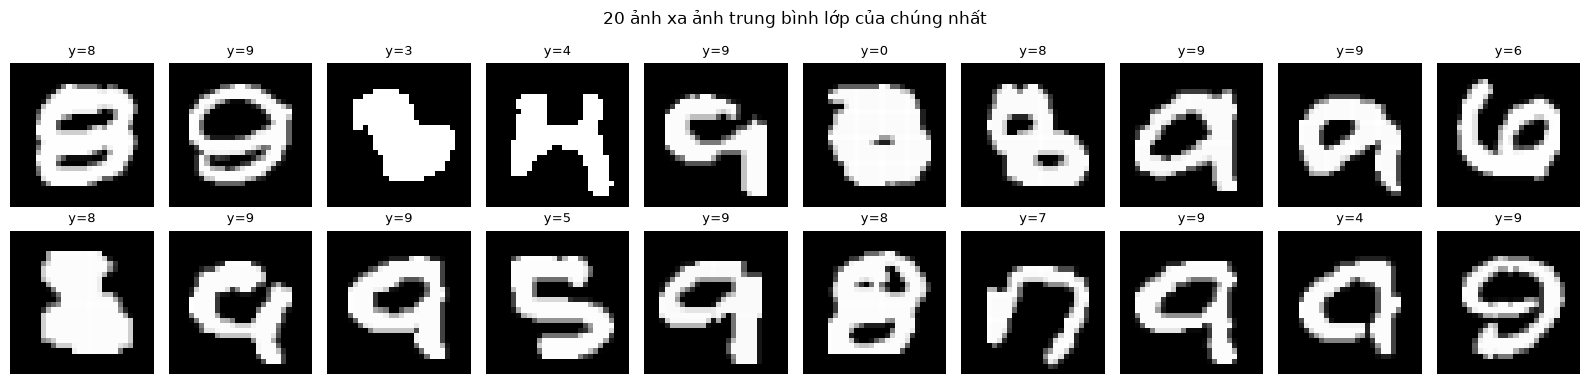

0    1789.4
1    1182.5
2    1807.7
3    1694.6
4    1616.0
5    1746.3
6    1656.0
7    1541.1
8    1706.5
9    1563.6
Name: Khoảng cách TB tới mean lớp, dtype: float64


In [20]:
flat_f = X_train.reshape(len(X_train), -1).astype(np.float32)
dist_to_mean = np.linalg.norm(flat_f - mean_imgs.reshape(10, -1)[y_train], axis=1)

top = np.argsort(dist_to_mean)[::-1][:20]
fig, axes = plt.subplots(2, 10, figsize=(16, 4))
for a, i in zip(axes.ravel(), top):
    a.imshow(X_train[i], cmap="gray")
    a.set_title(f"y={y_train[i]}", fontsize=9)
    a.axis("off")
plt.suptitle("20 ảnh xa ảnh trung bình lớp của chúng nhất")
plt.tight_layout()
plt.show()

print(pd.Series(dist_to_mean).groupby(y_train).mean().round(1).rename("Khoảng cách TB tới mean lớp"))

# 12. So sánh train và test

,Mean,Std,Tỷ lệ pixel = 0
Train,33.3184,78.5675,0.8088
Test,33.7912,79.1725,0.8072


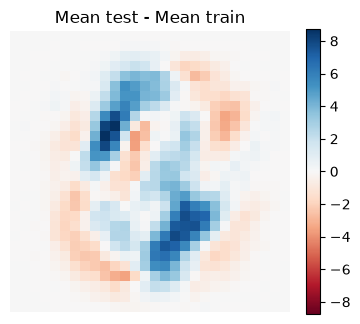

Chênh lệch tuyệt đối lớn nhất của mean theo pixel: 8.74 (thang 0-255)


In [21]:
cmp = pd.DataFrame(
    {
        "Mean": [X_train.mean(), X_test.mean()],
        "Std": [X_train.std(), X_test.std()],
        "Tỷ lệ pixel = 0": [np.mean(X_train == 0), np.mean(X_test == 0)],
    },
    index=["Train", "Test"],
)
display(cmp.round(4))

diff = X_test.mean(axis=0) - X_train.mean(axis=0)
plt.figure(figsize=(4, 4))
plt.imshow(diff, cmap="RdBu", vmin=-abs(diff).max(), vmax=abs(diff).max())
plt.title("Mean test - Mean train")
plt.colorbar(fraction=0.046)
plt.axis("off")
plt.show()

print(f"Chênh lệch tuyệt đối lớn nhất của mean theo pixel: {abs(diff).max():.2f} (thang 0-255)")

**Nhận xét:** nếu các thống kê của train và test gần giống nhau và bản đồ chênh lệch gần 0, hai tập cùng phân phối và có thể dùng test để đánh giá đáng tin cậy.

# 13. Kết luận và đề xuất tiền xử lý

**Cấu trúc dữ liệu**
- Train 60.000 ảnh, ảnh xám 28×28, kiểu `uint8`, giá trị 0 đến 255, 10 nhãn (0 đến 9).
- Mean = 33,32 và Std = 78,57 (thang 0-255), tương đương 0,1307 và 0,3081 (thang 0-1).
- Khoảng 80,9% pixel bằng 0 (nền đen); dữ liệu thưa và lệch mạnh về phía 0.

**Chất lượng và phân bố**
- Không có giá trị thiếu (kiểu `uint8`), nhãn hợp lệ; xem mục 3 để biết số ảnh trùng lặp, ảnh trống và rò rỉ train/test.
- Các lớp gần cân bằng (lệch nhẹ, xem mục 5), không cần oversample hay undersample.

**Đặc điểm hình ảnh**
- Thông tin tập trung ở vùng giữa ảnh; có nhiều vị trí viền luôn bằng 0.
- Có sự đa dạng cách viết trong cùng một lớp (ảnh std, outlier).
- Một số cặp lớp dễ nhầm lẫn (mục 10), có thể thấy rõ trong t-SNE.

**Đề xuất tiền xử lý và mô hình**
1. Chia `X / 255.0` về [0, 1], hoặc chuẩn hóa `(x - 0.1307) / 0.3081`.
2. Flatten thành 784 chiều cho mô hình cổ điển (có thể giảm chiều bằng PCA), hoặc giữ `(28, 28, 1)` cho CNN.
3. Tách validation từ train bằng **stratified split**; giữ test để đánh giá cuối cùng.
4. Dùng accuracy kèm confusion matrix và F1 macro; chú ý các cặp lớp dễ nhầm.
5. Có thể thêm augmentation nhẹ (xoay, dịch vài pixel) để tăng độ bền với kiểu viết.